# Semieix tubular a flexió amb forat transversal i canvi de secció

**DiAM — Exercici 03f.** Càlcul analític de:

1. les sol·licitacions a les seccions del forat i del canvi de diàmetre;
2. els factors de concentració de tensions $K_t$, les tensions nominals $\sigma_0$ i màximes $\sigma_{\max}$, la secció crítica i el coeficient de seguretat respecte a $S_\mathrm{ut}$.

Unitats: N, mm, MPa (N/mm²), N·mm.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Dades

In [2]:
F = 20_000.0        # [N]   càrrega transversal a l'extrem lliure
L = 210.0           # [mm]  distància de la cara de la placa a la força

D = 50.0            # [mm]  diàmetre exterior del tram gran (on hi ha el forat)
d = 40.0            # [mm]  diàmetre exterior del tram petit
d_i = 20.0          # [mm]  diàmetre del forat axial (interior)
a = 10.0            # [mm]  diàmetre del forat transversal
r = 1.0             # [mm]  radi d'acord del canvi de diàmetre

x_forat = 30.0      # [mm]  posició del forat (des de la cara de la placa)
x_canvi = 60.0      # [mm]  posició del canvi de diàmetre

S_ut = 1800.0       # [MPa] resistència a tracció del 100Cr6 templat

Kt_canvi_grafica = 2.48   # K_t llegit a la gràfica A-15-9 de Shigley (per comparar)


## 1) Sol·licitacions

El semieix és un voladís encastat a la placa ($x=0$) amb la força $F$ a $x=L$. En qualsevol secció:

$$V(x)=F, \qquad M_f(x)=F\,(L-x)$$

In [3]:
def moment_flector(x):
    """Moment flector d'un voladís amb càrrega F a x = L."""
    return F * (L - x)


V = F
M_forat = moment_flector(x_forat)
M_canvi = moment_flector(x_canvi)
M_encast = moment_flector(0.0)

print(f"Esforç tallant V                     = {V/1000:8.1f} kN")
print(f"Moment a l'encastament  (x =   0 mm) = {M_encast/1000:8.1f} N·m")
print(f"Moment al forat         (x = {x_forat:3.0f} mm) = {M_forat/1000:8.1f} N·m")
print(f"Moment al canvi secció  (x = {x_canvi:3.0f} mm) = {M_canvi/1000:8.1f} N·m")

Esforç tallant V                     =     20.0 kN
Moment a l'encastament  (x =   0 mm) =   4200.0 N·m
Moment al forat         (x =  30 mm) =   3600.0 N·m
Moment al canvi secció  (x =  60 mm) =   3000.0 N·m


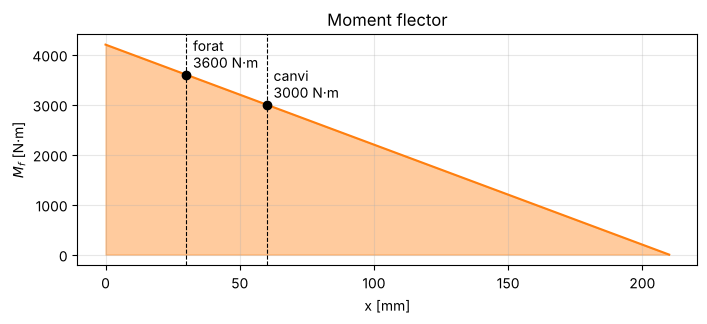

In [4]:
x = np.linspace(0, L, 200)
fig, ax = plt.subplots(figsize=(8, 3))
ax.fill_between(x, moment_flector(x) / 1000, color="tab:orange", alpha=0.4)
ax.plot(x, moment_flector(x) / 1000, color="tab:orange")
for xs, nom in [(x_forat, "forat"), (x_canvi, "canvi")]:
    ax.axvline(xs, ls="--", color="k", lw=0.8)
    ax.plot(xs, moment_flector(xs) / 1000, "ko")
    ax.annotate(f"{nom}\n{moment_flector(xs)/1000:.0f} N·m",
                (xs, moment_flector(xs) / 1000), xytext=(5, 5),
                textcoords="offset points")
ax.set_xlabel("x [mm]")
ax.set_ylabel("$M_f$ [N·m]")
ax.set_title("Moment flector")
ax.grid(alpha=0.3)
plt.show()

L'esforç tallant provoca una tensió tangencial màxima a la fibra neutra. Se'n calcula l'ordre de magnitud a la secció petita per comprovar que és petita en comparació amb les tensions de flexió.

In [5]:
def modul_resistent_tub(D_ext, D_int):
    """Mòdul resistent a flexió d'un tub: Z = pi (D^4 - d^4) / (32 D)."""
    return np.pi * (D_ext**4 - D_int**4) / (32.0 * D_ext)


def area_tub(D_ext, D_int):
    return np.pi / 4.0 * (D_ext**2 - D_int**2)


tau_max = 2.0 * V / area_tub(d, d_i)
print(f"Tensió tangencial màxima (tallant) = {tau_max:.1f} MPa")

Tensió tangencial màxima (tallant) = 42.4 MPa


## 2) Concentració de tensions

### Forat transversal: taula 3.1

La funció interpola linealment a la taula 3.1: primer en $a/D$ dins de cada columna i després en $d/D$ entre les columnes $d/D = 0,\ 0{,}6,\ 0{,}9$.

La tensió nominal es calcula amb el mòdul resistent reduït
$$Z_\text{net}=\frac{\pi A}{32D}\left(D^4-d^4\right)$$

In [6]:
def K_t_forat_flexio(a_D, d_D):
    """Retorna (A, K_t) per a la flexió d'una barra rodona o un tub amb un
    forat transversal, interpolant linealment a la taula 3.1.

    a_D : relació a/D (diàmetre del forat / diàmetre exterior)
    d_D : relació d/D (diàmetre interior / diàmetre exterior); 0 si és massís

    Primer s'interpola cada columna (d/D fix) en funció de a/D i després
    s'interpola el resultat en funció de d/D.
    """
    # --- Dades de la taula 3.1 ---
    t_a_D = np.array([0.050, 0.075, 0.10, 0.125, 0.15, 0.175,
                      0.20, 0.225, 0.25, 0.275, 0.30])
    t_d_D = np.array([0.0, 0.6, 0.9])

    # Files: a/D; columnes: d/D = 0, 0.6, 0.9
    t_A = np.array([
        [0.88, 0.91, 0.92],
        [0.86, 0.88, 0.89],
        [0.83, 0.85, 0.86],
        [0.80, 0.82, 0.82],
        [0.76, 0.79, 0.79],
        [0.72, 0.75, 0.76],
        [0.68, 0.72, 0.73],
        [0.65, 0.68, 0.69],
        [0.61, 0.64, 0.67],
        [0.58, 0.61, 0.66],
        [0.54, 0.58, 0.64],
    ])
    t_Kt = np.array([
        [2.42, 2.55, 2.63],
        [2.35, 2.43, 2.55],
        [2.27, 2.36, 2.49],
        [2.20, 2.32, 2.41],
        [2.15, 2.29, 2.39],
        [2.10, 2.26, 2.38],
        [2.07, 2.23, 2.39],
        [2.04, 2.21, 2.40],
        [2.00, 2.18, 2.42],
        [1.97, 2.16, 2.48],
        [1.94, 2.14, 2.52],
    ])

    # --- Comprovació del rang ---
    if not (t_a_D[0] <= a_D <= t_a_D[-1]):
        raise ValueError(f"a/D = {a_D:.3f} fora del rang de la taula 3.1")
    if not (t_d_D[0] <= d_D <= t_d_D[-1]):
        raise ValueError(f"d/D = {d_D:.3f} fora del rang de la taula 3.1")

    # --- Interpolació lineal doble ---
    def interpola(taula):
        valors_columna = [np.interp(a_D, t_a_D, taula[:, j])
                          for j in range(len(t_d_D))]
        return np.interp(d_D, t_d_D, valors_columna)

    A = interpola(t_A)
    K_t = interpola(t_Kt)
    return A, K_t


In [7]:
a_D = a / D
dD_forat = d_i / D
A_forat, Kt_forat = K_t_forat_flexio(a_D, dD_forat)

Z_net = A_forat * modul_resistent_tub(D, d_i)   # Z_net = pi A (D^4-d^4)/(32 D)
sigma0_forat = M_forat / Z_net
sigmamax_forat = Kt_forat * sigma0_forat
SF_forat = S_ut / sigmamax_forat

print(f"a/D = {a_D:.3f},  d/D = {dD_forat:.3f}")
print(f"A   = {A_forat:.3f},  K_t = {Kt_forat:.3f}")
print(f"Z_net     = {Z_net:.1f} mm^3")
print(f"sigma_0   = {sigma0_forat:.1f} MPa")
print(f"sigma_max = {sigmamax_forat:.1f} MPa")

a/D = 0.200,  d/D = 0.400
A   = 0.707,  K_t = 2.177
Z_net     = 8450.1 mm^3
sigma_0   = 426.0 MPa
sigma_max = 927.3 MPa


### Canvi de diàmetre amb arrodoniment

$K_t$ s'obté amb una expressió aproximada per a un rodó amb canvi de secció a flexió. La tensió nominal es calcula a la secció de diàmetre petit:
$$Z=\frac{\pi}{32\,d}\left(d^4-d_i^4\right)$$

In [8]:
def K_t_rodo_flexio(D_d, r_d, i_flag=1):
    # Calcula K_t d'un rodó sotmès a flexió amb canvi de secció D -> d.
    # D = diàmetre gran; d = diàmetre petit; r = radi de l'entalla
    # D_d : relació D/d; r_d : relació r/d
    # i_flag : =1 -> K_t per tensió normal,  !=1 -> K_t per von Mises
    if i_flag == 1:
        K_t = (0.632 + 0.377 * D_d**(-4.4) + r_d**(-0.5)
               * ((-0.14 - 0.363 * D_d**2 + 0.503 * D_d**4)
                  / (1 - 2.39 * D_d**2 + 3.368 * D_d**4))**0.5)
    else:
        K_t = (0.622 + 0.38 * D_d**(-4.3) + r_d**(-0.5)
               * ((-0.322 - 0.277 * D_d**2 + 0.599 * D_d**4)
                  / (1 - 2.55 * D_d**2 + 5.27 * D_d**4))**0.5)
    return K_t


In [9]:
D_d = D / d
r_d = r / d
Kt_canvi = K_t_rodo_flexio(D_d, r_d)

Z_canvi = modul_resistent_tub(d, d_i)            # secció de diàmetre petit
sigma0_canvi = M_canvi / Z_canvi
sigmamax_canvi = Kt_canvi * sigma0_canvi
SF_canvi = S_ut / sigmamax_canvi

print(f"D/d = {D_d:.3f},  r/d = {r_d:.3f}")
print(f"K_t       = {Kt_canvi:.3f}")
print(f"Z         = {Z_canvi:.1f} mm^3")
print(f"sigma_0   = {sigma0_canvi:.1f} MPa")
print(f"sigma_max = {sigmamax_canvi:.1f} MPa")

D/d = 1.250,  r/d = 0.025
K_t       = 2.722
Z         = 5890.5 mm^3
sigma_0   = 509.3 MPa
sigma_max = 1386.1 MPa


## Resum i secció crítica

In [10]:
print(f"{'':16s}{'M [N·m]':>10s}{'K_t':>8s}{'sigma_0':>10s}{'sigma_max':>12s}{'SF':>8s}")
print(f"{'':16s}{'':>10s}{'':>8s}{'[MPa]':>10s}{'[MPa]':>12s}{'':>8s}")
print("-" * 64)
for nom, M, Kt, s0, smax, SF in [
        ("Forat", M_forat, Kt_forat, sigma0_forat, sigmamax_forat, SF_forat),
        ("Canvi secció", M_canvi, Kt_canvi, sigma0_canvi, sigmamax_canvi, SF_canvi)]:
    print(f"{nom:16s}{M/1000:10.1f}{Kt:8.3f}{s0:10.1f}{smax:12.1f}{SF:8.2f}")

if sigmamax_forat >= sigmamax_canvi:
    critica, smax_c, smax_a = "el forat", sigmamax_forat, sigmamax_canvi
else:
    critica, smax_c, smax_a = "el canvi de secció", sigmamax_canvi, sigmamax_forat
dif = 100.0 * (smax_c - smax_a) / smax_a
print()
print(f"Secció crítica: {critica} (sigma_max {dif:.1f} % superior a l'altra discontinuïtat)")
print(f"Coeficient de seguretat mínim: SF = {S_ut / smax_c:.2f}")

                   M [N·m]     K_t   sigma_0   sigma_max      SF
                                       [MPa]       [MPa]        
----------------------------------------------------------------
Forat               3600.0   2.177     426.0       927.3    1.94
Canvi secció        3000.0   2.722     509.3      1386.1    1.30

Secció crítica: el canvi de secció (sigma_max 49.5 % superior a l'altra discontinuïtat)
Coeficient de seguretat mínim: SF = 1.30


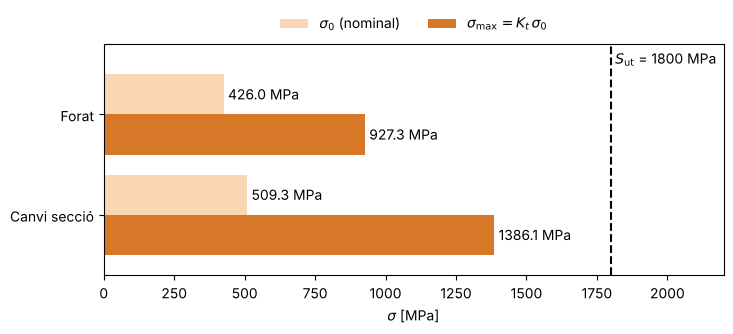

In [11]:
noms = ["Forat", "Canvi secció"]
s0 = [sigma0_forat, sigma0_canvi]
smax = [sigmamax_forat, sigmamax_canvi]
y = np.arange(len(noms))

fig, ax = plt.subplots(figsize=(8, 3))
ax.barh(y - 0.2, s0, height=0.4, color="#FAD7B4", label=r"$\sigma_0$ (nominal)")
ax.barh(y + 0.2, smax, height=0.4, color="#D67828", label=r"$\sigma_{\max}=K_t\,\sigma_0$")
for yi, v0, vm in zip(y, s0, smax):
    ax.text(v0 + 15, yi - 0.2, f"{v0:.1f} MPa", va="center")
    ax.text(vm + 15, yi + 0.2, f"{vm:.1f} MPa", va="center")
ax.axvline(S_ut, ls="--", color="k")
ax.text(S_ut + 15, -0.55, r"$S_\mathrm{ut}$ = " + f"{S_ut:.0f} MPa", va="center")
ax.set_yticks(y, noms)
ax.set_ylim(len(noms) - 0.4, -0.7)
ax.set_xlim(0, 2200)
ax.set_xlabel(r"$\sigma$ [MPa]")
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
plt.show()

## Comparació amb el $K_t$ llegit a la gràfica

L'expressió aproximada dona un $K_t$ del canvi de secció més alt que el valor llegit a la gràfica A-15-9 de Shigley. Amb $r = 1$ mm la diferència entre les dues fonts és apreciable, però en tots dos casos la secció crítica és la del canvi de secció.

In [12]:
sigmamax_canvi_graf = Kt_canvi_grafica * sigma0_canvi
SF_canvi_graf = S_ut / sigmamax_canvi_graf

print(f"K_t funció  = {Kt_canvi:.3f}  ->  sigma_max = {sigmamax_canvi:6.1f} MPa,  SF = {SF_canvi:.2f}")
print(f"K_t gràfica = {Kt_canvi_grafica:.3f}  ->  sigma_max = {sigmamax_canvi_graf:6.1f} MPa,  SF = {SF_canvi_graf:.2f}")
print(f"Diferència en K_t: {100*(Kt_canvi/Kt_canvi_grafica-1):.1f} %")
critica_graf = "el forat" if sigmamax_forat >= sigmamax_canvi_graf else "el canvi de secció"
print(f"Amb el K_t de la gràfica, la secció crítica seria {critica_graf}.")

K_t funció  = 2.722  ->  sigma_max = 1386.1 MPa,  SF = 1.30
K_t gràfica = 2.480  ->  sigma_max = 1263.1 MPa,  SF = 1.43
Diferència en K_t: 9.7 %
Amb el K_t de la gràfica, la secció crítica seria el canvi de secció.
